# Can my Apple Watch tell me when to slow down?

**Contents**

0. Abstract
1. Background
2. Idea and pipeline
3. Data
4. Module A: how much of my heart rate is just movement?
5. Module B: when is my heart rate higher than movement explains?
6. Module C: how recovered am I this morning?
7. Module D: what predicts tomorrow, and what should I do this weekend?
8. Ethics and limits
9. Discussion
10. AI statement and references

## 0. Abstract

I wanted to know if my Apple Watch can warn me before I burn out. Over 13 days (Oct 6 to 18, 2026) I collected about 8,000 heart-rate readings, steps, sleep and overnight signals from the watch, labelled my calendar, and rated how stressful each event felt. I cut everything into 5-minute windows and built the pipeline in four modules, where each one uses what the previous one learned.

**Module A** predicts my heart rate from movement. On days the models never saw, the best ones reach an error of about 8.6 bpm and explain about half of the variance (R² ≈ 0.55), against 12.9 bpm for guessing my average. **Module B** studies the other half, the heart rate that movement can't explain. While I am sitting, it is about one standard deviation higher in live class, work and high-stress tasks than at rest, and a hidden Markov model turns it into calm and elevated stretches. It does not follow my own stress ratings, so it measures load, not whether the load was good or bad. **Module C** gives a morning readiness score from five overnight signals compared with my own baseline. Right now it mostly reflects how long I slept. **Module D** tries to predict tomorrow's readiness from today. With only 7 usable days, no model beats guessing the average, so the weekend advice is built from simple rules on my own numbers instead.

The main lesson is that the methods work, but 13 days are not enough to trust anything at the level of whole days. More weeks of data and better self-ratings are the next step.

## 1. Background

I recently bought my mom an Apple Watch. She's not the most tech-savvy person, so before giving it to her I took it on a "test drive" to learn how to use it myself and then teach her.

I quickly realised it records a lot of useful data, but it doesn't really give you a good way to work with that data or get insights beyond the surface level (like your heart rate).

Minerva is especially hard on my body. I spend long hours in front of the computer, the workload is big, my sleep is irregular, I change countries every 4 months, and I have a limited budget and limited time for good food and sport. In more trendy terms, it's very easy to burn out if you're not taking care of yourself. It took me 4 years to understand what that actually means for me. So for this assignment I want to look into my Apple Watch data and build different machine learning models that help me improve my lifestyle and prevent burn out.

**Inputs:**

1. **Apple Watch data:** heart rate, HRV, sleep, steps, and more.
2. **My calendar:** I label every day (class, study, work, social, travel, walks, nap, sick).
3. **How I feel:** I rated how stressful each calendar event felt (1 to 5) and whether it felt easy, normal or dreaded.

**What the pipeline does:** it turns the watch into something like a [Garmin "readiness" score](https://www.garmin.com/en-US/garmin-technology/running-science/physiological-measurements/training-readiness/) each morning, tells me which parts of the day my body was under load that movement cannot explain, and suggests how to spend the weekend based on the week before.

In [1]:
import importlib.util, subprocess, sys
# install anything missing into the Python this notebook is running on (first run only)
for pkg, mod in [("numpy", "numpy"), ("pandas", "pandas"), ("scipy", "scipy"), ("scikit-learn", "sklearn"), ("hmmlearn", "hmmlearn"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import warnings, os, pickle
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from IPython.display import Markdown, display
sys.path.insert(0, "../src")
from features import build_windows, TAG_PRIORITY
from stage_a import FEATURES, MODELS, awake_table, oof, scores, run_grid, learning_curve
from stage_b import window_residuals
from daily import build_daily
import daily_models as dm
from hmm_states import choose_k, decode
import moments, advice
from pipeline import last_work_week

WATCH, CALF, OUT = "../data_private/watch", "../data_private/calendar_tags.csv", "../outputs"
os.makedirs(f"{OUT}/figures", exist_ok=True); os.makedirs("../data_private/cache", exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})

import hashlib, glob
# the cache key includes a fingerprint of the calendar file, the watch files and the code, so changed data or code is never served from old results
_fp = hashlib.md5(b"".join(open(f, "rb").read() for f in [CALF] + sorted(glob.glob(f"{WATCH}/*.csv")) + sorted(glob.glob("../src/*.py")))).hexdigest()[:8]
def cached(name, fn):
    # slow steps are saved once per data+code version (old cache files in ../data_private/cache can be deleted any time)
    p = f"../data_private/cache/{name}_{_fp}.pkl"
    if os.path.exists(p): return pickle.load(open(p, "rb"))
    r = fn(); pickle.dump(r, open(p, "wb")); return r

## 2. Idea and pipeline

I identified two things that make the raw watch data hard to use:

- Both a stressful class or going up the stairs can bump my heart rate to 100. To be able to infer stress, first I need to remove what movement can explain.
- Every body is different - A resting HR of 62 is great for one person and bad for another. Everything is compared to my other days.


So the pipeline is divided into four modules, and each one applies a class concept and compares it to my own baseline:

| Module | Question | Class idea | Beyond class |
|:--|:--|:--|:--|
| **A.** Heart rate from movement | How much of my HR is just movement? | regression, NN, trees (sessions 3, 4, 7), CV (9) | leave-one-day-out CV, learning curve |
| **B.** Calm / elevated states | When is my body under load that movement can't explain? | MLE for a spread (6) | hidden Markov model (22) |
| **C.** Morning readiness | How recovered am I today? | z-scores, bootstrap | personal leave-one-day-out baseline |
| **D.** Day-level prediction + weekend advice | What from today predicts tomorrow's recovery? What should I do this weekend? | bias–variance (11), collinearity (3) | ridge (15), PCA (16), shrinkage |

The work also touches all four pillars of the course:

1. ***Representation:*** 5-minute windows, lagged steps, z-scores, PCA.
2. ***Optimization:*** least squares and ridge in closed form, gradient descent for the network, EM for the HMM.
3. ***Probability:*** Gaussian noise and its MLE, the HMM, bootstrap and permutation tests.
4. ***Generalization:*** held-out days, learning curve, baselines, bias–variance.

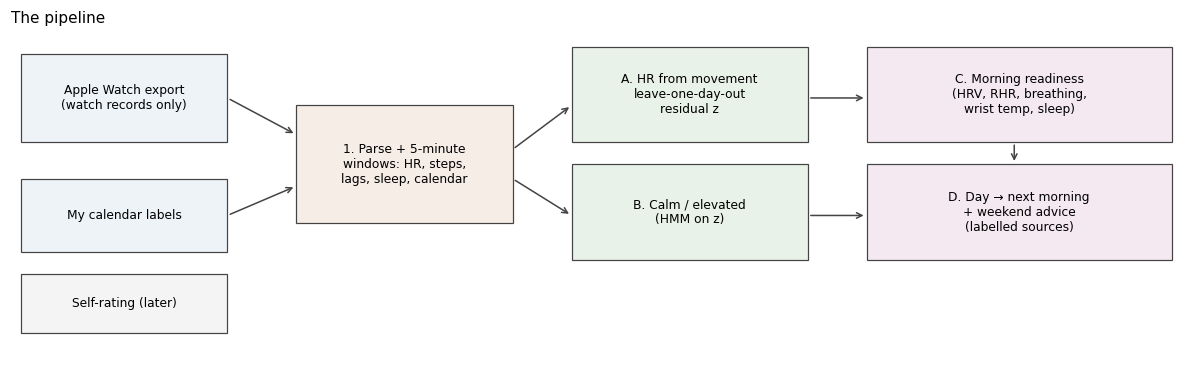

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.4)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(-.4, 4)
def box(x, y, w, h, t, c):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=c, ec="#444", lw=.8)); ax.text(x + w/2, y + h/2, t, ha="center", va="center", fontsize=8)
def arrow(x1, y1, x2, y2): ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color="#444"))
cols = ["#eef3f8", "#f5ede6", "#e9f2e9", "#f4e9f1"]
box(.1, 2.5, 2.1, 1.2, "Apple Watch export\n(watch records only)", cols[0]); box(.1, 1.0, 2.1, 1.0, "My calendar labels", cols[0]); box(.1, -.1, 2.1, .8, "Self-rating (later)", "#f4f4f4")
box(2.9, 1.4, 2.2, 1.6, "1. Parse + 5-minute\nwindows: HR, steps,\nlags, sleep, calendar", cols[1])
box(5.7, 2.5, 2.4, 1.3, "A. HR from movement\nleave-one-day-out\nresidual z", cols[2]); box(5.7, .9, 2.4, 1.3, "B. Calm / elevated\n(HMM on z)", cols[2])
box(8.7, 2.5, 3.1, 1.3, "C. Morning readiness\n(HRV, RHR, breathing,\nwrist temp, sleep)", cols[3]); box(8.7, .9, 3.1, 1.3, "D. Day → next morning\n+ weekend advice\n(labelled sources)", cols[3])
for a_, b_ in [((2.2, 3.1), (2.9, 2.6)), ((2.2, 1.5), (2.9, 1.9)), ((5.1, 2.4), (5.7, 3.0)), ((5.1, 2.0), (5.7, 1.5)), ((8.1, 3.1), (8.7, 3.1)), ((8.1, 1.5), (8.7, 1.5)), ((10.2, 2.5), (10.2, 2.2))]: arrow(*a_, *b_)
ax.set_title("The pipeline", loc="left"); plt.tight_layout(); plt.savefig(f"{OUT}/figures/01_pipeline.png", bbox_inches="tight"); plt.show()

## 3. Data

**Source and conversion.** Apple Health lets you export everything as one *export.xml* (about 270 MB for me). It is too big to load at once, so I stream-parse it (`parse_health.py`) and keep only records whose source is my **watch**. My phone also counts steps, so keeping both would double count every walk. Each record type (heart rate, steps, HRV, sleep, ...) becomes its own CSV.

**Windows.** The watch measures heart rate at irregular moments, a few times every few minutes, so I cut time into **5-minute windows** and compute the mean heart rate, the steps in the window, and the steps in the previous 5, 10 and 15 minutes and the last 30. I believe the lag is important for the model: even after you stop walking, your heart rate stays up for a while and only slowly comes back down to resting. I also mark sleep windows, workouts, and the calendar tags.

**Calendar labels.** Each label becomes a tag on every window it covers. When tags overlap, one wins based on this order: class > high-stress task > meeting > study > work > social > nap > travel > walk. On one of the days I was sick, so "unwell" is a background state that can overlap anything.

**Choices I made and why:**

- ***Active energy is computed by the watch partly from my heart rate.*** If I give it to the model as an input, the model can "explain" a heart rate raised by stress with a number that already contains that heart rate. The miss would shrink, and the stress signal I am looking for would shrink with it. So I test the model with and without active energy, to see how much it helps, but the stress signal in Module B comes from the version without it.
- ***Short sample.*** I have 13 days (Oct 6 to 18), mostly during fall break. That is not a "normal" Minerva week, so nothing here can be generalised to my whole semester.
- ***Missing nights.*** Two nights have no sleep record (after Oct 9 and after Oct 17, when I didn't wear the watch to bed), so the mornings after them have no readiness score. I leave them out instead of guessing.

In [3]:
w, nights = build_windows(WATCH, CALF)
w["cal_tag"] = w.cal_tag.replace("none", "rest")      # 2 windows had no label at all
a = awake_table(w)
src = pd.read_csv(CALF).source.value_counts().to_dict()
print("label rows by source:", src)
counts = {n: len(pd.read_csv(f"{WATCH}/{n}.csv")) for n in ["heart_rate", "steps", "hrv", "resting_hr", "resp_rate", "wrist_temp", "sleep", "workouts", "mindful"]}
print("watch records kept:", counts)
print(f"{len(a)} awake windows with a heart-rate reading, over {a.date.nunique()} days; {len(nights)} sleep sessions")
hours = (w[~w.asleep][[f'cal_{t}' for t in TAG_PRIORITY + ['unwell']]].sum() * 5 / 60).round(1).sort_values(ascending=False)
print("hours per calendar tag (awake):", hours.to_dict())

label rows by source: {'user': 55, 'inferred': 22, 'user_note_split': 4}
watch records kept: {'heart_rate': 8151, 'steps': 834, 'hrv': 68, 'resting_hr': 13, 'resp_rate': 459, 'wrist_temp': 11, 'sleep': 298, 'workouts': 4, 'mindful': 2}
1498 awake windows with a heart-rate reading, over 13 days; 12 sleep sessions
hours per calendar tag (awake): {'cal_rest': 91.1, 'cal_walk': 35.2, 'cal_travel': 26.3, 'cal_social': 19.6, 'cal_work': 11.3, 'cal_study': 10.6, 'cal_unwell': 8.3, 'cal_class_cs156': 4.5, 'cal_class_other': 4.5, 'cal_high_stress_task': 4.0, 'cal_meeting': 2.8, 'cal_social_late': 2.0, 'cal_nap': 2.0, 'cal_exercise': 1.0}


In [4]:
# what the modelling table looks like: one row per awake 5-minute window
cols = ["date", "hr", "steps", "steps_l1", "steps_l2", "steps_30", "active_kcal", "cal_tag", "felt_stress", "in_workout"]
a[cols].iloc[[0, 250, 500, 750, 1000, 1250]].round(1)

,date,hr,steps,steps_l1,steps_l2,steps_30,active_kcal,cal_tag,felt_stress,in_workout
t,,,,,,,,,,
2026-10-06 11:10:00+02:00,2026-10-06,62.0,0.0,0.0,0.0,0.0,0.0,study,NaN,0.0
2026-10-08 19:45:00+02:00,2026-10-08,79.0,0.0,0.0,0.0,5.0,2.5,class_other,5.0,0.0
2026-10-11 00:45:00+02:00,2026-10-11,67.0,4.0,0.0,0.0,5.0,0.5,rest,NaN,0.0
2026-10-13 13:15:00+02:00,2026-10-13,100.0,202.0,0.0,636.0,1609.0,3.7,walk,NaN,0.0
2026-10-14 20:40:00+02:00,2026-10-14,65.0,0.0,218.0,0.0,1540.0,14.2,social,1.0,0.0
2026-10-16 20:35:00+02:00,2026-10-16,98.4,0.0,860.0,0.0,1801.0,15.4,walk,NaN,0.0


After cleaning I have **1,498 awake windows with a heart-rate reading over 13 days**, plus 12 nights of sleep. Most of my awake time was rest (91 h), walking (35 h) and travel (26 h). Class is only 9 h, because most of this period was fall break. Of the 81 calendar label rows, 55 I wrote myself, 4 come from splitting my notes, and 22 are gaps I filled in afterwards (more on those in Ethics).

---
## 4. Module A: how much of my heart rate is just movement?

**Question:** If I know my steps (now and in the last 15 to 30 minutes), how well can I predict my heart rate?

**Logic:** What I *can't* predict is what I will use as a signal for stress. If there is no external factor raising my heart rate, the cause might be internal (aka stress).

**Target:** the mean heart rate of each 5-minute window, $HR_t$.

**Models** (all from class):

- **Linear regression.** Heart rate as a weighted sum of the inputs, with the weights chosen by least squares:
$$\widehat{HR}_t=\beta_0+\sum_j \beta_j x_{tj},\qquad \hat\beta=\arg\min_\beta \sum_t (HR_t-\widehat{HR}_t)^2=(X^\top X)^{-1}X^\top y$$
- **Random forest.** The average of 300 decision trees, each grown on a bootstrap sample of windows. It can learn non-linear shapes, like "heart rate stays high for a while after a walk":
$$\widehat{HR}_t=\frac{1}{300}\sum_{b=1}^{300}T_b(x_t)$$
- **Small neural network** with two hidden layers of 16 and 8 ReLU units, trained by gradient descent (Adam) on the squared error with a small L2 penalty:
$$\widehat{HR}_t=w_3^\top\,\mathrm{ReLU}\big(W_2\,\mathrm{ReLU}(W_1x_t+b_1)+b_2\big)+b_3$$

**Comparison.** I only have 13 days of quite messy data, so the goal of this module is to compare the models while changing one thing at a time:

| Condition | Why |
|:--|:--|
| 4 feature sets: steps only → + step lags → + active energy → + clock, time since waking, calendar | Which information actually helps? |
| 2 splits: random 5-fold vs **leave-one-day-out** | Neighbouring 5-minute windows are almost the same row. A random split lets the model peek at the neighbours of every test window. |
| 2 baselines: my overall mean, my mean for that hour of the day | If a model can't beat these, it hasn't learned anything about my movement that the clock doesn't already know. |

**Score.** I use the mean absolute error (MAE, in bpm) and $R^2$. For leave-one-day-out, every day $g$ is predicted by a model trained on the other 12 days:

$$\mathrm{MAE}_{\text{LODO}}=\frac{1}{N}\sum_{g}\sum_{t\in g}\left|HR_t-\widehat{HR}^{(-g)}_t\right|$$

In words: take one day out, train on the rest, predict every window of the missing day, and write down how far off each prediction is. Repeat for all 13 days, then average the misses over all $N$ windows. The $(-g)$ is there to remind me that the prediction for day $g$ comes from a model that never saw day $g$.

In [5]:
grid = cached("grid", lambda: run_grid(a))
grid.round(3).to_csv(f"{OUT}/stage_a_results.csv", index=False)
base = grid[grid.model.isin(["global mean", "hour-mean"])].pivot_table(index="model", columns="split", values=["MAE", "R2"]).round(2)
show = grid[~grid.model.isin(["global mean", "hour-mean"])].pivot_table(index=["features", "model"], columns="split", values=["MAE", "R2"]).round(2)
show = show.reindex(list(FEATURES.keys()), level=0)
print("BASELINES (bpm)\n", base, "\n\nMODELS\n", show)

BASELINES (bpm)
                           MAE                              R2              
split       leave-one-day-out random 5-fold leave-one-day-out random 5-fold
model                                                                      
global mean             12.88         12.73             -0.02         -0.00
hour-mean               12.37         11.45              0.09          0.21 

MODELS
                                                         MAE                              R2              
split                                     leave-one-day-out random 5-fold leave-one-day-out random 5-fold
features                model                                                                            
steps only              Linear regression             11.60         11.45              0.14          0.16
                        Neural net (16-8)             11.40         11.26              0.18          0.20
                        Random forest                 11.59    

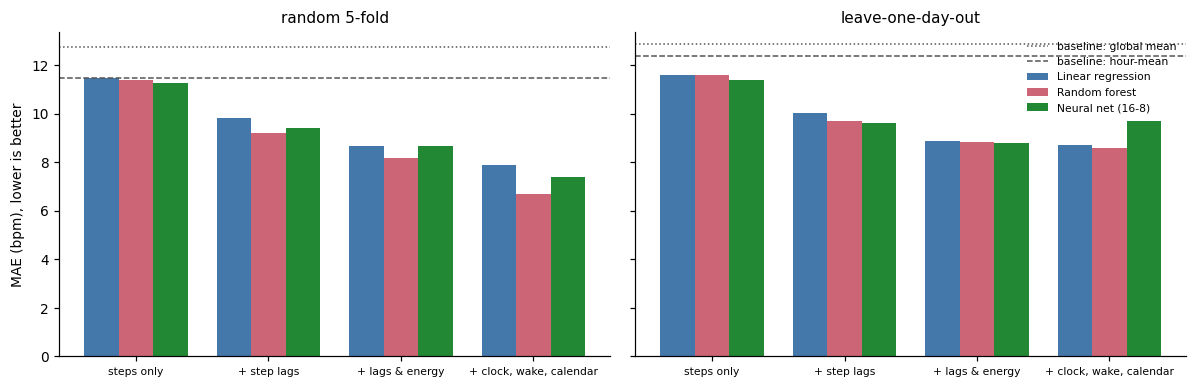

In [6]:
g = grid[~grid.model.isin(["global mean", "hour-mean"])]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for axi, kind in zip(ax, ["random 5-fold", "leave-one-day-out"]):
    x = np.arange(len(FEATURES)); wd = .26
    for i, (m, c) in enumerate(zip(MODELS, ["#4477aa", "#cc6677", "#228833"])):
        v = [g[(g.split == kind) & (g.features == f) & (g.model == m)].MAE.iloc[0] for f in FEATURES]
        axi.bar(x + (i - 1) * wd, v, wd, label=m, color=c)
    for nm, ls in [("global mean", ":"), ("hour-mean", "--")]:
        axi.axhline(grid[(grid.split == kind) & (grid.model == nm)].MAE.iloc[0], c="#555", ls=ls, lw=1, label=f"baseline: {nm}")
    axi.set_xticks(x); axi.set_xticklabels([f.replace(" + ", "\n+ ").replace("+ ", "+ ") for f in FEATURES], fontsize=7); axi.set_title(kind)
ax[0].set_ylabel("MAE (bpm), lower is better"); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/02_stage_a_comparison.png", bbox_inches="tight"); plt.show()

**What this means**

**Movement alone explains little.** With steps from the current window only, $R^2$ is 0.14 to 0.18. Adding the steps from the previous 15 to 30 minutes brings the error down from about 11.5 to 9.6–10.0 bpm and $R^2$ up to 0.38–0.44. This makes sense physiologically: when I stop walking, my heart doesn't drop back to resting straight away, it slows down over several minutes. So the earlier steps tell the model how much effort my heart is still recovering from, which the current window alone can't show.

**Active energy helps** (8.8 bpm, $R^2$ 0.55), but as explained in Data, it is partly computed from heart rate, so part of the gain is circular. I don't use it for the stress signal.

**Clock, time since waking and calendar don't help on a new day.** With them, the random forest gets 8.59 bpm on new days, against 8.81 without them. Under the random split, the same model suddenly looks much better (6.69). The gap is **data leakage**. K-fold cross-validation assumes the rows are independent, but my windows are not: a window looks almost exactly like the ones just before and after it (same activity, nearly the same heart rate). A random split puts those neighbours in the training set, and the clock and calendar tag tell the model exactly which moment it is looking at, so it can copy the neighbours' heart rate. That is memorising, not generalising. Leave-one-day-out hides the whole day, which is the real use case: the pipeline will always be predicting a day it hasn't seen.

**The neural network overfits the most.** With every feature it does well on the random split (7.37 bpm) but has the worst error on new days (9.71), and its $R^2$ falls from 0.64 to 0.42. It has the most parameters, so with only 13 days it learns patterns that belong to specific days instead of patterns that carry over. With this little data, the bigger model is not the better one.

**Baselines.** Guessing my overall average gives an error of 12.9 bpm, and guessing my average for that hour of the day gives 12.4. Every movement model beats both, but even the best one only gets to about 8.6 bpm. So roughly half of the ups and downs of my heart rate have nothing to do with movement, and that leftover half is exactly what I want to study next.

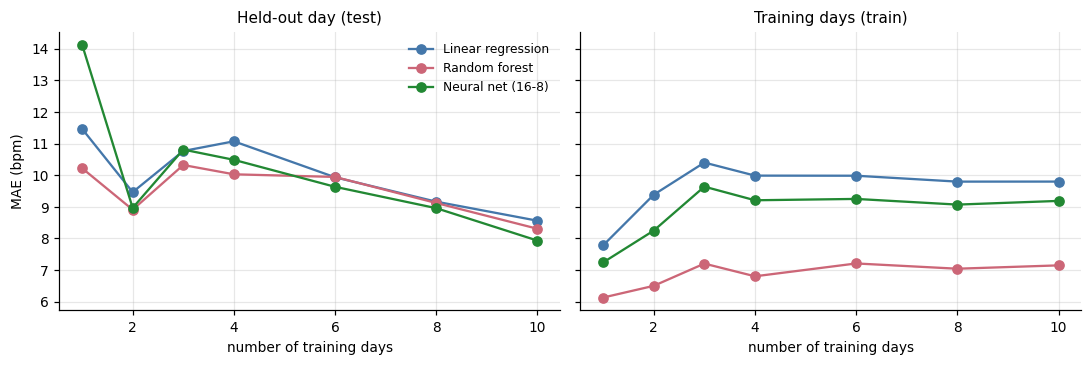

model,Linear regression,Neural net (16-8),Random forest
k,,,
1,11.5,14.1,10.2
2,9.5,9.0,8.9
3,10.8,10.8,10.3
4,11.1,10.5,10.0
6,9.9,9.6,9.9
8,9.2,9.0,9.1
10,8.6,7.9,8.3


In [7]:
lc = cached("lc", lambda: learning_curve(a, FEATURES["+ step lags"]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for m, c in zip(MODELS, ["#4477aa", "#cc6677", "#228833"]):
    d_ = lc[lc.model == m]; ax[0].plot(d_.k, d_.MAE, "o-", c=c, label=m); ax[1].plot(d_.k, d_.train_MAE, "o-", c=c, label=m)
ax[0].set_title("Held-out day (test)"); ax[1].set_title("Training days (train)")
for x in ax: x.set_xlabel("number of training days"); x.grid(alpha=.3)
ax[0].set_ylabel("MAE (bpm)"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/03_learning_curve.png", bbox_inches="tight"); plt.show()
lc.pivot(index="k", columns="model", values="MAE").round(1)

**Learning curve.** With one training day the models fit that day well (training error 6 to 8 bpm) and fail on a new one (10 to 14 bpm). As days are added, the two curves meet: from 6 to 10 days, training and test error are about the same, and test error keeps falling (7.9 to 8.6 bpm at 10 days). So the early error was variance, from too few days, and more days still help at 10. The curve is noisy, because each point is the average of a few random draws and a single test day is a small sample. **I can't tell where it levels off yet, so more weeks would make this module better.**

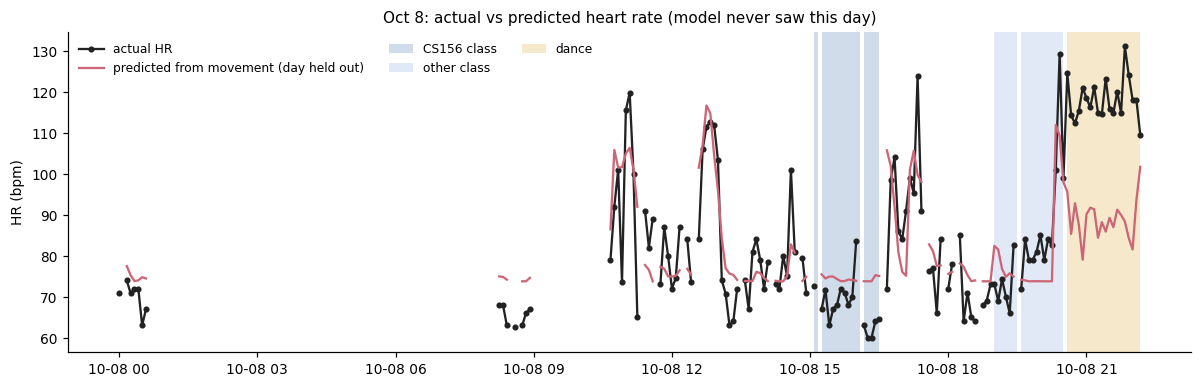

In [8]:
aw, info = cached("resid", lambda: window_residuals(w))
day = aw[aw.date == "2026-10-08"]
fig, ax = plt.subplots(figsize=(11, 3.6))
full = day[["hr", "pred"]].reindex(pd.date_range(day.index.min(), day.index.max(), freq="5min"))
ax.plot(full.index, full.hr, "o-", ms=3, c="#222", label="actual HR"); ax.plot(full.index, full.pred, "-", c="#cc6677", label="predicted from movement (day held out)")
def shade(mask, color, label):
    first = True
    for t in day.index[mask.values]:
        ax.axvspan(t, t + pd.Timedelta("5min"), color=color, alpha=.25, lw=0, label=label if first else None); first = False
shade(day.cal_tag == "class_cs156", "#4477aa", "CS156 class"); shade(day.cal_tag == "class_other", "#88aadd", "other class"); shade(day.workout.str.contains("Dance"), "#ddaa33", "dance")
ax.set_ylabel("HR (bpm)"); ax.legend(frameon=False, ncol=3, fontsize=8); ax.set_title("Oct 8: actual vs predicted heart rate (model never saw this day)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/04_pred_vs_actual.png", bbox_inches="tight"); plt.show()

Oct 8 is a day the model never saw. The prediction follows the shape of the day, rising with my walks and the dance class, but it misses the fastest peaks, like travelling (117 bpm against 89 predicted, probably rushing to catch the subway). It is also a good reminder that one class is not the average class: on this day my CS156 class sat slightly *below* the prediction (68 vs 74 bpm). The class effect in Module B is an average over three classes, not something that shows up every time.

## 5. Module B: when is my heart rate higher than movement explains?

**Question:** When I am sitting still, is my heart rate higher than movement can explain, and does that line up with what my calendar says I was doing?

**Logic:** Module A gave me a model that predicts heart rate from movement. The part it misses is the signal I need. I use the neural network with step lags (no active energy) and only take its predictions on days it never saw (leave-one-day-out), so the model can't "memorise" the day it is judging.

**Step 1: how big is a "normal" miss?** The miss (residual) is $r_t = HR_t-\widehat{HR}_t$. To compare misses across days I need their spread $\sigma$. I estimate it only from sitting windows (no steps in the last 15 minutes and no workout), because there movement has nothing left to explain. If the misses are Gaussian with mean 0, the likelihood is $L(\sigma)=\prod_t \mathcal N(r_t\mid 0,\sigma^2)$. Taking the log and setting the derivative to zero gives the MLE (session 6):

$$\hat\sigma^2=\frac{1}{N_{\text{sit}}}\sum_{t\in\text{sit}} r_t^2,\qquad \hat\sigma = 10.2\ \text{bpm}$$

The MLE divides by $N$, not $N-1$, so it is slightly biased low, but with 438 sitting windows the difference is 0.2%.

**Step 2: standardise and smooth.**

$$z_t=\frac{r_t}{\hat\sigma},\qquad \mathrm{UHR}_t=\frac{z_t+z_{t-1}+z_{t-2}}{3}$$

$z_t$ says how many "typical misses" my heart rate is above the movement prediction. One 5-minute reading is noisy, so the **unexplained heart rate (UHR)** averages the last 15 minutes. This way a single spike can't trigger it, but a longer stretch can.

                  windows  mean_z  mean_HR
cal_tag                                   
rest                  218   -0.56    68.30
study                  24   -0.25    71.52
meeting                 3    0.43    78.17
class_other            14    0.26    76.39
class_cs156            24    0.56    79.86
high_stress_task        8    0.80    81.44
work                    9    0.93    82.44
travel                 88    0.48    78.09
walk                   31    0.55    79.97
social                 19    0.34    77.88

sigma_r = 10.2 bpm | CS156 class vs rest: n=24 vs 218, mean z 0.56 vs -0.56, Mann-Whitney p=0.0000


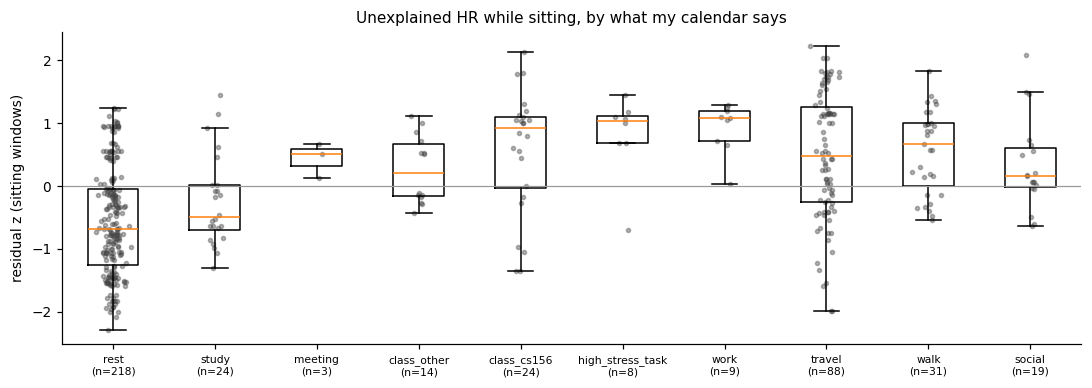

In [9]:
sed = aw[aw.sedentary]
order = ["rest", "study", "meeting", "class_other", "class_cs156", "high_stress_task", "work", "travel", "walk", "social"]
tab = sed.groupby("cal_tag").agg(windows=("z", "size"), mean_z=("z", "mean"), mean_HR=("hr", "mean")).reindex(order).round(2)
c, o = sed[sed.cal_tag == "class_cs156"].z, sed[sed.cal_tag == "rest"].z
mw = stats.mannwhitneyu(c, o)
print(tab); print(f"\nsigma_r = {info['sigma']:.1f} bpm | CS156 class vs rest: n={len(c)} vs {len(o)}, mean z {c.mean():.2f} vs {o.mean():.2f}, Mann-Whitney p={mw.pvalue:.4f}")
fig, ax = plt.subplots(figsize=(10, 3.6)); data = [sed[sed.cal_tag == t].z.values for t in order]
ax.boxplot(data, labels=[f"{t}\n(n={len(x)})" for t, x in zip(order, data)], showfliers=False)
for i, x in enumerate(data, 1): ax.scatter(np.random.default_rng(1).normal(i, .06, len(x)), x, s=7, alpha=.4, c="#444")
ax.axhline(0, c="#999", lw=.8); ax.set_ylabel("residual z (sitting windows)"); ax.tick_params(axis="x", labelsize=7); ax.set_title("Unexplained HR while sitting, by what my calendar says")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/05_residual_by_calendar.png", bbox_inches="tight"); plt.show()

**What this means**

**The residual moves the way my labels say it should.** Sitting in a CS156 class, my heart rate is about 1.1 standard deviations above sitting at rest (0.56 vs −0.56, roughly 11 bpm), and work and high-stress tasks are even higher (0.93 and 0.80). Studying on my own is only slightly above rest (−0.25). My intuition is that what raises it is not thinking but being "on": live class, being cold-called, a deadline.

**Caveats!** The Mann-Whitney test gives p < 0.0001 for class vs rest, but neighbouring windows are not independent (one class gives many windows that are almost the same reading), so the real evidence is weaker than that p-value suggests. Several tags have fewer than 10 windows. Also, some "rest" labels were filled in afterwards for gaps I couldn't remember, partly based on low heart rate, which pushes rest down. Without them, the gap is 0.56 vs −0.46, so the conclusion holds.

**Can it separate labelled windows?** I use AUC (session 9): the probability that a random window with the label scores higher than a random window without it. 0.5 is a coin flip. The first table compares sitting windows only; the second compares each label against every other awake window, including when I'm moving.

In [10]:
a2, hmm, order_ = cached("hmm2", lambda: decode(aw, 2))
s = a2[a2.sedentary].dropna(subset=["p_elevated", "uhr"])
rows = []
for lab in ["class_cs156", "work", "travel", "high_stress_task"]:
    sub = s[s.cal_tag.isin([lab, "rest"])]; y = (sub.cal_tag == lab).astype(int)
    rows.append(dict(label=lab, n_label=int(y.sum()), n_rest=int((1 - y).sum()), **{k: round(roc_auc_score(y, sub[k]), 2) for k in ["hr", "z", "uhr", "p_elevated"]}))
sit = pd.DataFrame(rows).set_index("label")
allw = a2[~a2.in_workout.astype(bool)].dropna(subset=["p_elevated", "uhr"]); rows = []
for lab in ["class_cs156", "work", "travel", "high_stress_task", "meeting", "study"]:
    y = (allw.cal_tag == lab).astype(int)
    rows.append(dict(label=lab, n_label=int(y.sum()), n_other=int((1 - y).sum()), **{k: round(roc_auc_score(y, allw[k]), 2) for k in ["hr", "z", "uhr", "p_elevated"]}))
print("SITTING WINDOWS, label vs rest"); print(sit.to_string()); print("\nALL AWAKE WINDOWS (not in workouts), label vs everything else"); print(pd.DataFrame(rows).set_index("label").to_string())

SITTING WINDOWS, label vs rest
                  n_label  n_rest    hr     z   uhr  p_elevated
label                                                          
class_cs156            17     123  0.84  0.83  0.83        0.85
work                    8     123  0.89  0.92  0.90        0.91
travel                 45     123  0.71  0.72  0.76        0.72
high_stress_task        2     123  0.84  0.87  0.95        0.88

ALL AWAKE WINDOWS (not in workouts), label vs everything else
                  n_label  n_other    hr     z   uhr  p_elevated
label                                                           
class_cs156            31      854  0.50  0.62  0.63        0.63
work                   28      857  0.55  0.72  0.74        0.76
travel                125      760  0.51  0.53  0.53        0.52
high_stress_task       20      865  0.61  0.56  0.54        0.59
meeting                19      866  0.59  0.51  0.55        0.58
study                  58      827  0.52  0.59  0.61        0.61


**Why it adds nothing while sitting.** The first table only compares sitting windows, so movement is already the same in every window, and $z$ is basically my raw heart rate shifted by a constant (0.84 vs 0.83).

**Where it helps: comparing across activities.** The second table compares class windows with every other awake window, including walking, travel and dancing. Here raw heart rate can't pick out class at all (AUC 0.50): sitting in class (about 80 bpm on average) is often lower than a brisk walk, so on raw heart rate class looks like an average window.

So the comparison is **not** my heart rate when walking. $z$ compares each window with what Module A predicts my heart rate *should* be for the movement in that window. For example, a walk at 100 bpm where the model expected 100 gets $z\approx 0$ (fully explained by movement), while sitting in class at 80 bpm where the model expected 70 gets $z\approx +1$ (10 bpm the steps can't explain). Every window is measured against its own movement-based baseline, and only then compared with the others. That is why $z$ beats raw heart rate for class (0.50 → 0.62), work (0.55 → 0.72) and studying (0.52 → 0.59).

It doesn't help for travel (0.51 → 0.53) or meetings (0.59 → 0.51). Travel mixes sitting on a bus with walking with bags, so there is no consistent extra load to find, and meetings only have 19 windows. **So it is a real but modest signal (AUC 0.6 to 0.7 where it works), not a "stress detector".**

**One check on my own method.** I estimated $\hat\sigma$ from sitting windows and then used the same $\hat\sigma$ for every window. That is only fair if the model misses by about the same amount whether I sit or move:

In [11]:
# is one sigma fair for every window? compare the size of the model's misses while sitting and while moving
r = aw.hr - aw.pred
spread = r.groupby(aw.sedentary.map({True: "sitting", False: "moving"})).agg(
    windows="size", rms_miss_bpm=lambda x: np.sqrt((x ** 2).mean()), mean_miss_bpm="mean").round(2)
print(spread.to_string())
print(f"\nz divides every miss by sigma = {info['sigma']:.1f} bpm (from sitting windows), so a typical miss while moving "
      f"shows up as |z| ≈ {spread.loc['moving', 'rms_miss_bpm'] / info['sigma']:.2f} instead of 1")

           windows  rms_miss_bpm  mean_miss_bpm
sedentary                                      
moving        1060         12.96           0.45
sitting        438         10.17          -0.69

z divides every miss by sigma = 10.2 bpm (from sitting windows), so a typical miss while moving shows up as |z| ≈ 1.27 instead of 1


It doesn't hold perfectly. While I move, the model misses by about 13 bpm instead of 10, so a typical miss during a walk looks about 27% bigger in $z$ than it should. Part of what looks "elevated" while moving is therefore just the model being less accurate during movement. This is why I trust the sitting results most, and it is a clear thing to fix next (for example a separate $\hat\sigma$ for sitting and moving).

### Hidden Markov model: calm and elevated states

**Why:** a single $z$ is noisy, and stress (assuming my data has it) comes in stretches, not in single 5-minute windows. A threshold like "UHR > 1.5" is also arbitrary. A **hidden Markov model** (session 22, I read ahead) assumes every window has a hidden state, calm or elevated, that I never see directly, only through $z$:

$$P(s_t=j\mid s_{t-1}=i)=A_{ij},\qquad z_t\mid s_t=j\ \sim\ \mathcal N(\mu_j,\sigma_j^2)$$

The first formula says that the state of this window depends only on the state of the window before, and $A_{ij}$ is the probability of moving from state $i$ to state $j$. The second says that once I know the state, $z$ comes from a normal distribution with that state's own mean and spread: the calm state should produce low $z$ values and the elevated state high ones. If $A$ is "sticky" (high values on its diagonal), the model prefers to stay in a state, so one odd reading doesn't flip it.

To fit the model I need the likelihood of a whole day. Done naively, this means summing over every possible sequence of states, $2^T$ of them. The **forward recursion** does it in $T$ steps:

$$\alpha_t(j)=\Big[\sum_i \alpha_{t-1}(i)\,A_{ij}\Big]\;\mathcal N(z_t\mid\mu_j,\sigma_j^2),\qquad P(z_1,\dots,z_T)=\sum_j\alpha_T(j)$$

$\alpha_t(j)$ is the probability of seeing $z_1,\dots,z_t$ and ending in state $j$. Each step reuses the step before: add up every state I could have come from, times the chance of jumping to $j$, times how likely the new $z$ is under $j$.

**EM** (expectation–maximisation) is how the model learns $\mu$, $\sigma$ and $A$ without any labels. It is maximum likelihood again (session 6), but with a hidden variable: I don't know which state each window was in, so I can't just average. EM alternates two steps. The E-step uses the current parameters to compute, for every window, the probability that it was calm or elevated. The M-step re-estimates $\mu$, $\sigma$ and $A$ as averages weighted by those probabilities. Every round increases the likelihood, until it stops changing. EM can get stuck on a local maximum, so I run it from 5 random starts and keep the best. I wrote the forward pass by hand and checked it against hmmlearn. Only $z$ goes in: my first version also used steps, and it learned "moving vs still" instead of "calm vs elevated".

**How many states?** I held out each day, fit on the others, and scored the held-out log-likelihood per window:

In [12]:
ck = cached("choose_k", lambda: choose_k(aw)); print(ck.round(3).to_string(index=False))
mu = hmm.means_.ravel()[order_]; sd = np.sqrt(hmm.covars_.ravel()[order_]); A = hmm.transmat_[order_][:, order_]
print(f"\ncalm: mean z {mu[0]:+.2f} (sd {sd[0]:.2f}) | elevated: mean z {mu[1]:+.2f} (sd {sd[1]:.2f})")
print(f"stay probability: calm {A[0,0]:.2f}, elevated {A[1,1]:.2f}  (typical stretch = {1/(1-A[0,0])*5:.0f} and {1/(1-A[1,1])*5:.0f} minutes)")

 K  heldout_loglik_per_window
 1                     -1.531
 2                     -1.372
 3                     -1.361
 4                     -1.301

calm: mean z -0.82 (sd 0.77) | elevated: mean z +0.73 (sd 0.80)
stay probability: calm 0.92, elevated 0.91  (typical stretch = 63 and 56 minutes)


The big jump is from 1 to 2 states (+0.16 per window). After that the gains are small (+0.01 from 2 to 3). **I fixed K = 2 for interpretability, not because the likelihood chose it**, for two reasons:

- **I can't check what extra states mean.** With 13 days I have no way to tell whether states 3 and 4 are real patterns of my body or just noise from a few days.
- **Two states match two actions.** When I'm calm, I keep going. When I've been elevated for a while, I take a break. A third state would only be useful once I know what it means and what I should do differently in it.

**The two states.** Calm has mean $z$ −0.82, elevated +0.73 (both with SD about 0.8). Each state stays put with probability 0.92 and 0.91 per window. The expected length of a stretch is $5\ \text{min}/(1-A_{ii})$, so a typical calm stretch lasts about an hour and an elevated one about 55 minutes.

sitting windows: 438 | threshold rule flags 1.8%, HMM flags 45.2% | agreement 0.57
state flips per window: HMM 0.07 vs raw 'z > 0' 0.25  (lower = steadier)

elevated share of awake windows by calendar tag
cal_tag         high_stress_task  meeting  social_late   work  social  class_cs156  study  class_other  travel  nap    walk    rest
windows                    33.00    28.00        18.00  44.00  126.00        46.00  88.00        32.00  215.00  8.0  272.00  537.00
elevated_share              0.88     0.86         0.83   0.77    0.72         0.61   0.61         0.53    0.53  0.5    0.48    0.28


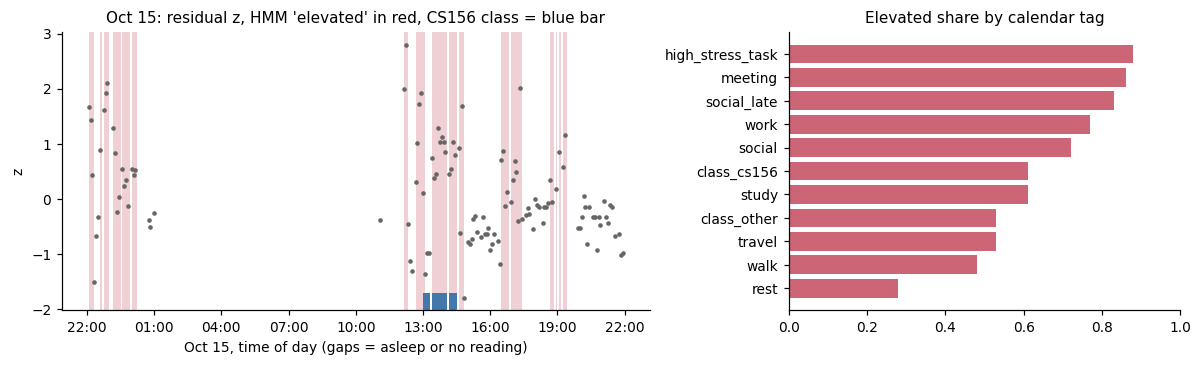

In [13]:
sd_ = a2[a2.sedentary]
thr = (sd_.uhr > 1.5); hm = (sd_.state == 1)
flip = lambda x: float((x.astype(int).diff().abs().fillna(0)).mean())
print(f"sitting windows: {len(sd_)} | threshold rule flags {thr.mean():.1%}, HMM flags {hm.mean():.1%} | agreement {(thr == hm).mean():.2f}")
print(f"state flips per window: HMM {flip(a2.state):.2f} vs raw 'z > 0' {flip(a2.z > 0):.2f}  (lower = steadier)")
by = a2.groupby("cal_tag").agg(windows=("state", "size"), elevated_share=("state", "mean")).round(2).sort_values("elevated_share", ascending=False)
print("\nelevated share of awake windows by calendar tag"); print(by.T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
day = a2[a2.date == "2026-10-15"]; ax[0].plot(day.index, day.z, ".", c="#666", ms=4)
for t, st in zip(day.index, day.state):
    if st == 1: ax[0].axvspan(t, t + pd.Timedelta("5min"), color="#cc6677", alpha=.3, lw=0)
for t in day.index[(day.cal_tag == "class_cs156").values]: ax[0].axvspan(t, t + pd.Timedelta("5min"), ymax=.06, color="#4477aa", lw=0)
import matplotlib.dates as mdates
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax[0].set_xlabel("Oct 15, time of day (gaps = asleep or no reading)")
ax[0].set_title("Oct 15: residual z, HMM 'elevated' in red, CS156 class = blue bar"); ax[0].set_ylabel("z")
b = by.drop(index=["nap"], errors="ignore"); ax[1].barh(b.index[::-1], b.elevated_share[::-1], color="#cc6677"); ax[1].set_title("Elevated share by calendar tag"); ax[1].set_xlim(0, 1)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/06_hmm_states.png", bbox_inches="tight"); plt.show()

**HMM vs the threshold rule.** "UHR > 1.5" flags only 1.8% of sitting windows, because 1.5 SD of a 15-minute average is a high bar. The HMM flags 45% and is steadier: 0.07 state switches per window vs 0.25 for a raw "$z>0$" rule. The elevated share by tag ranks my activities in a sensible order: high-stress task 88%, meeting 86%, late social 83%, work 77%, social 72%, class and study 61%, travel 53%, walk 48%, rest 28%.

**What this means:** the ranking makes sense, but "elevated" is relative to my own average, so a large part of any day will be elevated by construction. It is useful for comparing days and activities (the weekend advice uses it), not as an absolute "you are stressed" alarm.

### Does it follow how I felt?

If the states measure stress, and not just "something is happening", the windows I rated 5 (very stressful) should look more elevated than the windows I rated 1 (relaxed).

In [14]:
x = a2[~a2.in_workout.astype(bool)].dropna(subset=["z", "uhr", "p_elevated"])
lab = x.felt_stress.map({1: "1 relaxed", 4: "4 stressful", 5: "5 very stressful"}).fillna("unrated")
t_all = x.groupby(lab).agg(windows=("z", "size"), mean_hr=("hr", "mean"), mean_z=("z", "mean"), elevated_share=("state", "mean")).round(2)
xs = x[x.sedentary]; lab_s = xs.felt_stress.map({1: "1 relaxed", 4: "4 stressful", 5: "5 very stressful"}).fillna("unrated")
t_sit = xs.groupby(lab_s).agg(windows=("z", "size"), mean_hr=("hr", "mean"), mean_z=("z", "mean"), elevated_share=("state", "mean")).round(2)
print("ALL AWAKE WINDOWS (not workouts)"); print(t_all.to_string()); print("\nSITTING WINDOWS ONLY"); print(t_sit.to_string())
r = x.dropna(subset=["felt_stress"]); rows = []
for lo, hi in [(1, 5), (1, 4), (4, 5)]:
    sub = r[r.felt_stress.isin([lo, hi])]; y = (sub.felt_stress == hi).astype(int)
    rows.append(dict(compare=f"{hi} vs {lo}", n_high=int(y.sum()), n_low=int((1 - y).sum()), **{k: round(roc_auc_score(y, sub[k]), 2) for k in ["hr", "z", "uhr", "p_elevated"]}))
print("\nAUC: can the scores tell a higher rating from a lower one?"); print(pd.DataFrame(rows).set_index("compare").to_string())
print("\nSpearman correlation of z with my rating (rated windows):", round(stats.spearmanr(r.z, r.felt_stress)[0], 2), f"(n={len(r)})")

ALL AWAKE WINDOWS (not workouts)
                  windows  mean_hr  mean_z  elevated_share
felt_stress                                               
1 relaxed              56    92.93    0.33            0.68
4 stressful           104    81.82    0.17            0.58
5 very stressful       84    83.59    0.23            0.65
unrated               641    80.95   -0.16            0.44

SITTING WINDOWS ONLY
                  windows  mean_hr  mean_z  elevated_share
felt_stress                                               
1 relaxed               2    91.50    1.79            1.00
4 stressful            43    77.11    0.38            0.58
5 very stressful       29    80.68    0.65            0.76
unrated               179    71.61   -0.25            0.38

AUC: can the scores tell a higher rating from a lower one?
         n_high  n_low    hr     z   uhr  p_elevated
compare                                             
5 vs 1       84     56  0.34  0.48  0.50        0.51
4 vs 1      104   

**No.** Relaxed windows are as elevated as stressful ones. The AUC for 5 vs 1 is 0.48 for $z$ (a coin flip), and the Spearman correlation between $z$ and my rating is −0.02. Raw heart rate even points the wrong way (AUC 0.34), because my relaxed events were dancing and walking with friends. It is a weak test for two reasons: I gave one rating per event, not per moment, and the ratings follow the event type (every class a 5, every social event a 1), so there are really only a few independent ratings.

> **Honest claim:** the pipeline finds load that movement can't explain, but it can't tell good load from bad.

## 6. Module C: how recovered am I this morning?

Module B looks at my day. Module C looks at the night after it, and asks whether my body recovered.

**Question:** How recovered am I this morning, compared to my usual?

**Logic:** Garmin's readiness score compares your overnight signals with your own baseline. I do the same with the five signals my watch records overnight:

| Signal | Better when |
|:--|:--|
| HRV (log of SDNN, night samples) | higher |
| Resting heart rate | lower |
| Respiratory rate | lower |
| Sleeping wrist temperature | close to my norm (either direction is worse) |
| Hours asleep | higher |

**Method:** each signal becomes a z-score against my other mornings, flipped so that positive always means "better". The composite is their average, passed through the normal CDF:

$$z_k=\pm\frac{x_k-\hat\mu_k}{\hat\sigma_k},\qquad C=\frac{1}{K}\sum_k z_k,\qquad \text{score}=100\,\Phi(C)$$

$\Phi$ maps $C$ to 0–100, so 50 is a typical morning for me and 84 is one SD better. Wrist temperature uses $-|z|$, because a fever and a cold room are both bad. HRV is log-transformed because a few very high readings skew it. I need at least 3 of the 5 signals for a score.

**Two choices that matter:**

- **Leave-one-day-out baseline.** A morning is never compared to a baseline that includes itself. Otherwise a bad morning pulls the mean toward itself and looks less bad than it was.
- **Bootstrap band.** I resample the baseline days 500 times and recompute the score; the 5th to 95th percentile is a 90% band. With about 10 mornings the baseline itself is uncertain, and the band shows how much.

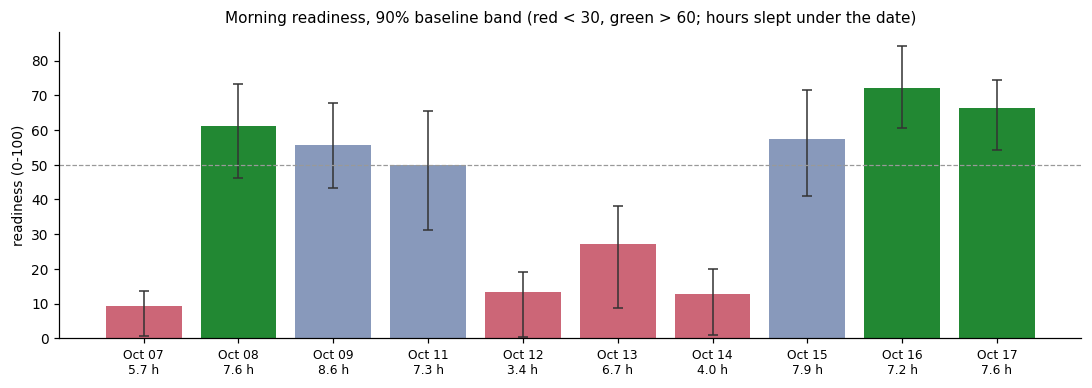

correlation of the composite with hours slept: 0.83 | with resting HR: -0.81 | n=10 mornings
HRV samples per night: [2, 2, 2, 2, 1, 1, 1, 3, 3, 2]


In [15]:
d, aa, info_d, mor = cached("daily", lambda: build_daily(w, WATCH))
m = mor.dropna(subset=["score"])
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(m))
ax.bar(x, m.score, color=np.where(m.score < 30, "#cc6677", np.where(m.score > 60, "#228833", "#8899bb")))
ax.errorbar(x, m.score, yerr=[m.score - m.score_lo, m.score_hi - m.score], fmt="none", ecolor="#333", capsize=3, lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"{i:%b %d}\n{h:.1f} h" for i, h in zip(m.index, m.asleep_h)], fontsize=8)
ax.axhline(50, c="#999", lw=.8, ls="--"); ax.set_ylabel("readiness (0-100)"); ax.set_title("Morning readiness, 90% baseline band (red < 30, green > 60; hours slept under the date)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/07_readiness.png", bbox_inches="tight"); plt.show()
ok = m.dropna(subset=["composite"])
print("correlation of the composite with hours slept:", round(np.corrcoef(ok.composite, ok.asleep_h)[0, 1], 2), "| with resting HR:", round(np.corrcoef(ok.composite, ok.rhr)[0, 1], 2), f"| n={len(ok)} mornings")
print("HRV samples per night:", m.n_hrv.astype(int).tolist())

**What this means**

The three lowest mornings (Oct 7, 12 and 14, scores 9 to 13) follow the shortest nights (5.7, 3.4 and 4.0 h). The composite correlates 0.83 with hours slept and −0.81 with resting heart rate. So **right now the score mostly reads sleep length**, with resting heart rate backing it up. HRV should be the core of a recovery score, but the watch only records 1 to 3 HRV samples a night, so its z-score is too noisy to add much, and the bands are up to 35 points wide. On Oct 12 I was also sick from 6:00 am, so I can't separate sleep from illness there and won't claim the score "detected" it.

### Good load vs "bad" load

Module B showed that the watch can't tell good load from bad. The watch sees the same fast heart in a class and in a dance class, but for my mind they are opposites: friends, dancing and walking are refreshing, while class, work and travelling are costly. So I group the tags by what they do to me (editable in `features.py`): **costly** = classes, high-stress tasks, meetings, work, travel; **refreshing** = social time, dancing, walking; everything else is neutral.

In [16]:
from features import VALENCE, REFRESHING_WORKOUTS
val = pd.Series("neutral", index=aw.index)
val[aw.cal_tag.isin(VALENCE["costly"])] = "costly"
val[aw.cal_tag.isin(VALENCE["refreshing"]) | aw.workout.str.contains("|".join(REFRESHING_WORKOUTS))] = "refreshing"
body = aw.assign(valence=val).groupby("valence").agg(windows=("z", "size"), mean_hr=("hr", "mean"), mean_z=("z", "mean"))
body["elevated_share"] = a2.assign(valence=val.reindex(a2.index)).groupby("valence").state.mean()
print("WHAT THE BODY SHOWS (all awake windows; elevated share excludes workouts)"); print(body.round(2).to_string())
dd = d[["costly_h", "refreshing_h", "m_score"]].rename(columns={"m_score": "next_morning_score"}); dd["costly_h"] = dd.costly_h.round(1); dd["refreshing_h"] = dd.refreshing_h.round(1)
print("\nHOURS PER DAY and the next morning's readiness"); print(dd.round(0).T.to_string())
ok = d.dropna(subset=["m_composite"])
print("\nSpearman with next-morning composite (n=%d days): costly hours %.2f, refreshing hours %.2f" % (len(ok), stats.spearmanr(ok.costly_h, ok.m_composite)[0], stats.spearmanr(ok.refreshing_h, ok.m_composite)[0]))

WHAT THE BODY SHOWS (all awake windows; elevated share excludes workouts)
            windows  mean_hr  mean_z  elevated_share
valence                                             
costly          398    81.76    0.22            0.62
neutral         655    75.48   -0.30            0.34
refreshing      445    92.89    0.28            0.56

HOURS PER DAY and the next morning's readiness
                    2026-10-06  2026-10-07  2026-10-08  2026-10-09  2026-10-10  2026-10-11  2026-10-12  2026-10-13  2026-10-14  2026-10-15  2026-10-16  2026-10-17  2026-10-18
costly_h                   2.0         9.0         7.0        12.0         0.0         0.0         0.0         6.0         9.0         3.0         0.0         0.0         4.0
refreshing_h               7.0         8.0         5.0         2.0         2.0         2.0         0.0        12.0         5.0         2.0         7.0         7.0         0.0
next_morning_score         9.0        61.0        56.0         NaN        50.0        13

Costly and refreshing time are both much more "elevated" than neutral time (62% and 56% vs 34%), and refreshing time even has the higher heart rate (93 vs 82 bpm), because that is where the walking and dancing are. **Heart rate alone can never say "this is good for me", only my labels can.**

**Do days with more hours of class, work and travel give me a worse readiness score the next morning, and days with more friends, dancing and walking a better one?** Not that I can see. Across 10 mornings, the Spearman correlation with next-morning readiness is +0.19 for costly hours (the opposite sign from my hypothesis) and −0.03 for refreshing hours, and with $n=10$ neither is distinguishable from zero. The clearest case points somewhere else: Oct 13 was my most "refreshing" day (12 h, mostly one long walk), and it was followed by one of my worst mornings (13), after only 4 hours of sleep. So **sleep may matter more than the type of load**. That is a hypothesis for more data, not a result yet.

## 7. Module D: what predicts tomorrow, and what should I do this weekend?

### D1. Predicting tomorrow's readiness (ridge)

**Question:** From what a day asked of me, can I predict tomorrow morning's readiness composite?

**Features (10).** I chose these myself, one or two for each thing I believe drains or restores me:

| What I think matters | Feature |
|:--|:--|
| physical load | daily strain $S$, steps, exercise minutes, hard effort after 21:00 |
| mental load | hours of class, study and work |
| environment | daylight minutes, noise, travel hours |
| social time | hours with friends |
| rest | hours slept the night before |

Strain combines Module B with time spent working hard: $S=z(M)+z(P)$, where $M$ is the share of my sitting windows with UHR > 1.5 and $P$ is the minutes spent in my own top-20% heart-rate zone.

**Which days can I use?** A day only counts if every feature and the next morning's score exist:

In [17]:
# which days can D1 use, and why are the others dropped?
x = dm.prepare(d)
rows = []
for day, row in x.iterrows():
    why = []
    if row.windows < 60:
        why.append(f"only {row.windows:.0f} awake windows with HR (need 60 to trust the day)")
    elif pd.isna(row.M):
        why.append(f"only {row.sed_windows:.0f} sitting windows (need 20 to trust M)")
    if pd.isna(row.this_asleep_h):
        why.append("no sleep record the night before")
    if pd.isna(row.m_composite):
        why.append("no readiness score the next morning")
    rows.append(dict(day=f"{day:%a %b %d}", usable="yes" if not why else "no", reason="; ".join(why)))
print(pd.DataFrame(rows).to_string(index=False))
print("\nusable days:", len(dm.usable(d, "m_composite")))

       day usable                                                                         reason
Tue Oct 06     no                                               no sleep record the night before
Wed Oct 07     no                       only 38 awake windows with HR (need 60 to trust the day)
Thu Oct 08    yes                                                                               
Fri Oct 09     no                                            no readiness score the next morning
Sat Oct 10     no only 18 sitting windows (need 20 to trust M); no sleep record the night before
Sun Oct 11    yes                                                                               
Mon Oct 12    yes                                                                               
Tue Oct 13    yes                                                                               
Wed Oct 14    yes                                                                               
Thu Oct 15    yes             

Six of the 13 days are missing a part, and each for a concrete reason. Oct 6 is the first day I wore the watch, so there is no night before it. On Oct 7 and Oct 10 I wore it too little to trust the day's strain. After Oct 9 and Oct 17 I didn't wear the watch to bed, so there is no next-morning score, and Oct 18 is the last day of the export. That leaves **7 usable days for 10 features**.

**Why plain least squares fails here.** Least squares needs $X^\top X$ to be invertible. With more features than days it can't be: 7 rows can't pin down 10 weights. On top of that, the features move together:

In [18]:
# collinearity: which features rise and fall together on the usable days?
D = dm.usable(d, "m_composite")
corr = D[dm.FEATS].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("most correlated feature pairs (7 usable days):\n" + pairs.head(5).round(2).to_string())
Z = (D[dm.FEATS] - D[dm.FEATS].mean()) / D[dm.FEATS].std(ddof=0)
print(f"\nrank of the standardised X: {np.linalg.matrix_rank(Z.values)} out of {len(dm.FEATS)} columns -> X'X cannot be inverted")

most correlated feature pairs (7 usable days):
noise_db  h_social_all    0.94
S         daylight_min    0.93
          steps_k         0.93
steps_k   daylight_min    0.91
S         h_travel        0.90

rank of the standardised X: 6 out of 10 columns -> X'X cannot be inverted


Steps, daylight, travel and strain are correlated at 0.84 to 0.93, and noise and social time at 0.94. The reason is my life, not the maths: on a travel day I walk more, I'm outside longer, and my heart rate is higher, so all four go up together (Oct 13 is the extreme case, with 25,000 steps and 4 hours of daylight). This is the **collinearity** problem from session 3. When two features always move together, the data can't say which one deserves the credit, so least squares can give one a huge positive weight and the other a huge negative weight, and both change completely if I remove a single day. **Ridge regression** (session 15) fixes this by adding a penalty on the size of the weights:

$$\hat\beta=\arg\min_\beta\ \|y-X\beta\|^2+\lambda\|\beta\|^2=(X^\top X+\lambda I)^{-1}X^\top y$$

Adding $\lambda I$ makes the matrix invertible for any $\lambda>0$, so there is always one answer, and the penalty spreads the credit across correlated features instead of letting it swing between them. $\lambda$ is the bias–variance dial from session 11: a small $\lambda$ is close to least squares (low bias, high variance), and a large $\lambda$ shrinks every weight toward 0, so the model just predicts the mean (high bias, no variance). I standardise $X$ so every feature is penalised on the same scale, and I wrote ridge from the closed form and checked it against scikit-learn.

**Comparison:** I pick $\lambda$ by leave-one-day-out error and compare ridge with three baselines: the mean of the other days, persistence (tomorrow = this morning), and KNN (the average of the 3 most similar days). To check that a good score isn't luck, a permutation test shuffles the target 300 times and repeats the whole $\lambda$ search each time (otherwise choosing $\lambda$ would flatter the real result).

usable days: 7 | features: 10
predict the mean              0.61
persistence (this morning)    0.53
KNN analog days               0.81
ridge, best lambda=1000       0.63
Name: leave-one-day-out MSE, dtype: float64
permutation test: p = 0.90
lambda 0.01: train 0.000, held-out 2.07 | lambda 1000: train 0.43, held-out 0.63


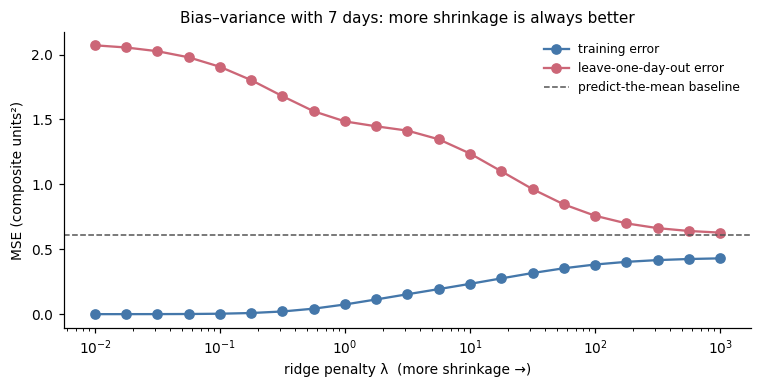

In [19]:
D = dm.usable(d, "m_composite"); y = D.m_composite.values
cur = dm.lodo_curve(D, dm.FEATS, "m_composite")
mean_mse = dm.mean_baseline_mse(y); pers = dm.persistence_mse(D, "this_composite", "m_composite"); knn = dm.knn_lodo_mse(D, dm.FEATS, "m_composite")
real, pval, null = cached("perm", lambda: dm.permutation_p(D, dm.FEATS, "m_composite", n=300))
best = cur.loc[cur.cv_mse.idxmin()]
print(f"usable days: {len(D)} | features: {len(dm.FEATS)}")
print(pd.Series({"predict the mean": mean_mse, "persistence (this morning)": pers, "KNN analog days": knn, f"ridge, best lambda={best.lam:.0f}": best.cv_mse}).round(2).rename("leave-one-day-out MSE"))
print(f"permutation test: p = {pval:.2f}")
print(f"lambda {cur.lam.iloc[0]:.2f}: train {cur.train_mse.iloc[0]:.3f}, held-out {cur.cv_mse.iloc[0]:.2f} | lambda {cur.lam.iloc[-1]:.0f}: train {cur.train_mse.iloc[-1]:.2f}, held-out {cur.cv_mse.iloc[-1]:.2f}")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(cur.lam, cur.train_mse, "o-", c="#4477aa", label="training error"); ax.semilogx(cur.lam, cur.cv_mse, "o-", c="#cc6677", label="leave-one-day-out error")
ax.axhline(mean_mse, c="#555", ls="--", lw=1, label="predict-the-mean baseline"); ax.set_xlabel("ridge penalty λ  (more shrinkage →)"); ax.set_ylabel("MSE (composite units²)")
ax.legend(frameon=False, fontsize=8); ax.set_title("Bias–variance with 7 days: more shrinkage is always better")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/08_ridge_lambda.png", bbox_inches="tight"); plt.show()

**What this means**

The result is negative. With almost no penalty ($\lambda=0.01$), ridge fits the 6 training days perfectly (training error 0.000) but misses the held-out day badly (2.07), which is overfitting: 10 weights are enough to memorise 6 days. As $\lambda$ grows, the held-out error drops, but it only reaches the level of guessing the average (0.61), and it gets there at the largest $\lambda$ I tried, where all the weights are almost zero. In other words, the best ridge model is the one that ignores the features. The permutation test agrees: shuffled targets do at least as well as the real ones 90% of the time ($p=0.90$). KNN is worse than the mean (0.81), because with 7 days the "most similar" days are not very similar. Persistence is a bit better (0.53), which only says that a good morning tends to follow a good morning.

So 13 days of data are not enough to predict recovery. This is the same message as the learning curve in Module A: with too few days the model memorises instead of generalising. The methods are ready, and the limit is the data. Every extra week adds 7 rows to this table, so I expect this module to become useful after a few months of wearing the watch.

### D2. Kinds of moments (PCA + k-means)

D1 needed whole days, and I only have 7. A single day, though, has about 100 windows, so the next question works at the level of windows, where I have plenty of data.

**Question:** Without any labels, what kinds of moments does my day contain?

**Method:** every awake window is described by 7 features: heart rate, $z$, log of steps in the last 30 minutes, physical effort, noise, and time of day as sin/cos (so 23:55 sits next to 00:05). After standardising, PCA (session 16) keeps 3 components that explain 40%, 15% and 14% of the variance (69% together), and k-means groups the windows into clusters in that space. The calendar tags are not used to build the groups, only afterwards to interpret them.

**How many groups?** To choose $k$ I used the **silhouette score**. For every window it compares how close the window is to its own cluster with how close it is to the nearest other cluster. It goes from −1 to 1: near 1 means tight, well-separated groups, and near 0 means the groups blend into each other. My score is low and flat for every $k$ from 2 to 7 (0.27 to 0.30), so my windows form a continuum rather than separate islands, and no $k$ is clearly "right". I fixed $k=4$ because four groups are easy to name and read.

                    windows      hr     z  steps_30  effort  noise_db  mean hour
calm and still          391   66.21 -0.86     43.58    3.22     59.20       9.23
moving, easy            464   82.85 -0.64    736.20    3.48     70.51      14.94
still but elevated      452   83.23  0.80     60.34    3.36     68.39      15.43
hard effort             191  111.88  1.49   1127.79    4.47     75.86      16.86

explained variance of 3 PCs: [0.4  0.15 0.14] | silhouette by k: {2: 0.29, 3: 0.27, 4: 0.27, 5: 0.29, 6: 0.3, 7: 0.3}
agreement with calendar tags (adjusted mutual information): 0.14 (0 = none, 1 = identical)


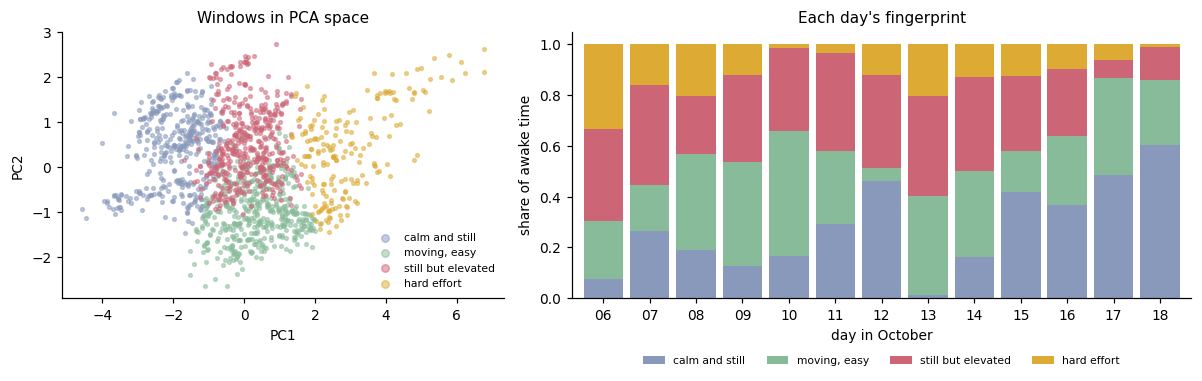

In [20]:
res = moments.fit_moments(aw, k=4)
am, prof = moments.describe(aw, res)
names = {}
rest = list(prof.index)
names[prof.hr.idxmax()] = "hard effort"; rest.remove(prof.hr.idxmax())
names[prof.loc[rest, "z"].idxmax()] = "still but elevated"; rest.remove(prof.loc[rest, "z"].idxmax())
names[prof.loc[rest, "hr"].idxmin()] = "calm and still"; rest.remove(prof.loc[rest, "hr"].idxmin())
names[rest[0]] = "moving, easy"
am["moment_name"] = am.moment.map(names); prof.index = [names[i] for i in prof.index]
print(prof.drop(columns="hour").join(prof.hour.rename("mean hour")).to_string())
print("\nexplained variance of 3 PCs:", res["pca"].explained_variance_ratio_.round(2), "| silhouette by k:", {k: round(v, 2) for k, v in res["silhouette"].items()})
print("agreement with calendar tags (adjusted mutual information):", round(moments.tag_agreement(am), 2), "(0 = none, 1 = identical)")
fp = moments.fingerprints(am).rename(columns={f"m{k}": v for k, v in names.items()})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1, 1.4]))
for k, c in zip(sorted(names), ["#8899bb", "#88bb99", "#cc6677", "#ddaa33"]):
    mk = res["labels"] == k; ax[0].scatter(res["P"][mk, 0], res["P"][mk, 1], s=6, alpha=.5, c=c, label=names[k])
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(frameon=False, fontsize=7, markerscale=2); ax[0].set_title("Windows in PCA space")
fp[[names[k] for k in sorted(names)]].plot.bar(stacked=True, ax=ax[1], color=["#8899bb", "#88bb99", "#cc6677", "#ddaa33"], width=.85)
ax[1].set_xticklabels([f"{i:%d}" for i in fp.index], rotation=0); ax[1].set_xlabel("day in October"); ax[1].set_ylabel("share of awake time"); ax[1].legend(frameon=False, fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.18)); ax[1].set_title("Each day's fingerprint")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/09_moments.png", bbox_inches="tight"); plt.show()

**What this means:** the clusters make sense: *calm and still* (66 bpm, mostly mornings), *moving, easy*, *still but elevated* (83 bpm while barely moving, mostly afternoons) and *hard effort* (112 bpm). **"Still but elevated" is the most important one for this assignment**, because it is the same pattern Module B found (a heart rate higher than movement explains), but here the clustering found it on its own, without a movement model or labels. Two very different methods pointing at the same thing makes me trust the signal more.

Each day also gets a fingerprint: the share of its awake time in each type of moment. Most days spend a third or more of the time *still but elevated*, except Oct 8, 15 and 16 (23 to 29%) and the weekend of Oct 17 to 18 (7 to 13%).

If the clusters were just my calendar in disguise, each cluster would match one tag. They don't: knowing a window's cluster tells me very little about its calendar tag (adjusted mutual information 0.14, where 0 means unrelated and 1 means identical). So the clusters describe the state of my body, not the activity I was doing. That makes them interesting to explore, but I don't use them to make decisions yet.

### D3. Weekend advice (a first version)

This part is an exploration that I will build on later. D1 showed that 7 days are not enough to learn what helps me recover, so for now the advice is a small set of simple rules on my own numbers. Every line says where it comes from, so I know how much to trust it:

| Source | Meaning |
|:--|:--|
| my data | this week compared to my other days: sleep debt, costly hours, elevated share, steps, noise |
| playbook | which activities went with better next mornings, shrunk toward zero |
| general guidance | standard recovery advice (sleep regularity, daylight, quiet), switched on by a rule |
| my stated preference | when strained, calm rest, not sport; when recovered, dancing counts as good strain |

The playbook compares next-morning readiness on days with and without at least 1 h of an activity. With so few days that difference is very noisy, so I shrink it toward zero, $\text{shrunk}=\text{raw}\cdot\frac{n}{n+3}$, and only call it "clear" with 4+ days and a bootstrap interval that excludes 0.

In [21]:
el = a2.groupby("date").state.mean()
pb = advice.playbook(d)
print("PLAYBOOK (next-morning composite, SD units; 'clear' needs 4+ days and an interval above/below 0)")
print(pb.round(2).to_string(index=False))
def show_plan(label, days):
    s = advice.week_summary(d, mor, el, pd.to_datetime(days)); plan = advice.weekend_plan(s, pb)
    txt = f"**{label}**\n\n" + "\n".join(f"- **{p['area']}** ({p['source']}): {p['advice']} *Why: {p['because']}*" for p in plan)
    display(Markdown(txt))
show_plan("Week of Oct 6 to 10, advice for the weekend of Oct 10-11", ["2026-10-06", "2026-10-07", "2026-10-08", "2026-10-09", "2026-10-10"])
show_plan("Week of Oct 12 to 16, advice for the weekend of Oct 17-18", [str(x.date()) for x in last_work_week(d)])

PLAYBOOK (next-morning composite, SD units; 'clear' needs 4+ days and an interval above/below 0)
   activity  days_with  raw_diff  shrunk_diff    lo   hi  clear
class_other          3      0.84         0.42  0.17 0.71  False
       walk          7      0.46         0.32 -0.25 0.83  False
       work          2      0.61         0.24  0.06 0.48  False
   exercise          1      0.59         0.15  0.06 0.42  False
        nap          1      0.49         0.12  0.04 0.33  False
     social          6      0.11         0.07 -0.39 0.55  False
      study          3      0.08         0.04 -0.40 0.43  False
class_cs156          3      0.08         0.04 -0.44 0.46  False
     travel          3     -0.02        -0.01 -0.38 0.29  False


**Week of Oct 6 to 10, advice for the weekend of Oct 10-11**

- **Sleep** (my data + general guidance): Aim for about 6.9 h on both nights and keep the wake-up within an hour of the weekday time. *Why: 1 short night(s) and 0.8 h of sleep debt this week (my usual is 6.6 h).*
- **Calm** (my data + general guidance): Two or three 15 to 20 minute calm blocks a day: slow breathing (a Mindfulness session on the watch logs it), a bath or quiet reading, no screens. *Why: 31 h of class, meetings, work, hard tasks and travel this week (costly week from 10 h); elevated-state time was +13 points vs my usual.*
- **Refresh** (my stated preference): Plan one low-key thing I find refreshing, like time with friends or a slow walk. Dance only if I feel recovered and am not ill. *Why: I find friends, dancing and walking refreshing, and class, work and travel costly; this week had 31 h costly vs 24 h refreshing.*
- **Movement** (my stated preference): No sport this weekend. Keep movement easy: a slow walk, stretching. *Why: My setting: strained weeks call for calming rest, not sport (RULES['calm_not_sport']).*
- **Daylight** (my data + general guidance): Get 30 to 60 minutes outside in daylight, ideally in the morning, at an easy pace. *Why: Desk-heavy week (28 h of class, study and work; steps at 88% of my median day).*
- **Quiet** (my data + general guidance): Keep one day low-input: few plans, little noise, no transit. *Why: Travel 11 h and average noise 63 dB this week.*
- **Playbook** (my data): Not enough days yet to say which activities help me most. Keep logging labels and mindful sessions. *Why: No activity has been seen on 4+ days with an interval that excludes zero.*

**Week of Oct 12 to 16, advice for the weekend of Oct 17-18**

- **Sleep** (my data + general guidance): Aim for about 8.1 h on both nights and keep the wake-up within an hour of the weekday time. *Why: 2 short night(s) and 5.8 h of sleep debt this week (my usual is 6.6 h).*
- **Calm** (my data + general guidance): Two or three 15 to 20 minute calm blocks a day: slow breathing (a Mindfulness session on the watch logs it), a bath or quiet reading, no screens. *Why: 18 h of class, meetings, work, hard tasks and travel this week (costly week from 10 h); elevated-state time was +3 points vs my usual.*
- **Refresh** (my stated preference): Plan one low-key thing I find refreshing, like time with friends or a slow walk. Dance only if I feel recovered and am not ill. *Why: I find friends, dancing and walking refreshing, and class, work and travel costly; this week had 18 h costly vs 26 h refreshing.*
- **Movement** (my stated preference): No sport this weekend. Keep movement easy: a slow walk, stretching. *Why: My setting: strained weeks call for calming rest, not sport (RULES['calm_not_sport']).*
- **Quiet** (my data + general guidance): Keep one day low-input: few plans, little noise, no transit. *Why: Travel 11 h and average noise 63 dB this week.*
- **Playbook** (my data): Not enough days yet to say which activities help me most. Keep logging labels and mindful sessions. *Why: No activity has been seen on 4+ days with an interval that excludes zero.*

**Does it make sense?**

1. **The rules fire for reasons I can see.** Oct 6 to 10 had 31 h of costly time (class, work and travel), which triggers the calm blocks, and 28 h at a desk, which triggers daylight. Oct 12 to 16 had 5.8 h of sleep debt and 2 short nights, so the sleep target goes up to 8.1 h.
2. **The playbook refuses to guess.** No activity has 4+ days with a clear interval, so it says "not enough days yet" instead of inventing a favourite activity.
3. **Looking back** (table below), the weekend of Oct 17 to 18 was much calmer than the weekdays before it (elevated share 6% and 5% vs 37 to 73%), with a long walk and 71 minutes of daylight on Oct 17. That is consistent with the advice, but two weekends of one person is not evidence that following it helps.

In [22]:
wk = d.loc[d.index.isin(pd.to_datetime(["2026-10-10", "2026-10-11", "2026-10-17", "2026-10-18"])), ["steps", "daylight_min", "noise_db", "m_score"]].copy()
wk.insert(0, "elevated_share", el.reindex(wk.index).round(2)); wk["m_score"] = wk.m_score.round(0); wk = wk.rename(columns={"m_score": "next_morning_score"})
print("weekdays (Oct 12-16) elevated share:", el.reindex(pd.to_datetime([str(x.date()) for x in last_work_week(d)])).round(2).tolist())
wk.round({"noise_db": 1, "elevated_share": 2})

weekdays (Oct 12-16) elevated share: [0.5, 0.73, 0.52, 0.47, 0.37]


,elevated_share,steps,daylight_min,noise_db,next_morning_score
2026-10-10,0.23,5943,0.0,69.2,50.0
2026-10-11,0.52,4405,34.0,60.5,13.0
2026-10-17,0.06,12200,71.0,54.4,NaN
2026-10-18,0.05,4265,0.0,69.2,NaN


## 8. Ethics and limits

- **The labels took so much work!** Everything I can check depends on me hand-labelling my calendar, which is "ghost work" in miniature (from the *Human Touch* reading). For anyone else, this is the biggest barrier to using the pipeline. I also let Claude suggest tags for 22 gaps I couldn't remember, based on time, heart rate and steps. That is circular (a label made from the signal I then test), so those rows are marked "inferred", kept out of the playbook, and I checked that the main result holds without them.
- **Privacy.** Heart rate, sleep and an "unwell" label are health data. Raw exports stay on my laptop and are git-ignored; the repository only has code and synthetic demo data.
- **Generalisation.** One person, 13 days, mostly fall break. It says nothing about my semester or about other people. Apple's HRV and active energy algorithms are proprietary, so I don't fully know what I am measuring.
- **My own method has gaps.** One $\hat\sigma$ for all windows makes misses while moving look bigger than they are (13 vs 10 bpm), and the strain score $S$ correlates 0.93 with steps over the usable days, so it still partly measures movement instead of load.
- **Not medical.** A heart rate above prediction can be caffeine, excitement, illness or stress, and the pipeline can't tell which. "Elevated" is relative to me.
- **Over-trusting a number.** A low score can make me feel worse on a day I feel fine. The bands, the source labels and the refusals to claim an effect are there so the score is a prompt to think, not an order.

## 9. Discussion

**What worked.** Movement from the last 15 to 30 minutes predicts my heart rate reasonably well on new days ($R^2$ up to 0.55), and what is left over follows my calendar: while sitting, live class, work and high-stress tasks are about 1 SD above rest, and studying barely is. The unsupervised clustering in D2 found the same "still but elevated" pattern without being told to look for it. The choice that mattered most was leave-one-day-out validation: a random split made clock and calendar features look great (6.7 bpm) when they weren't (8.6 on a new day).

**What didn't.** The movement-adjusted score is only modestly better than raw heart rate, and it doesn't follow my own stress ratings: it finds load, not whether the load was good or bad. Readiness is mostly sleep length, because HRV is sampled too rarely. The day-level model can't beat the mean with 7 days.

**Why.** Two causes run through every module: very little data (13 days, 7 usable for D1) and a noisy, proprietary sensor. The model that could learn the most (the neural network) was also the one that overfit the most, and the learning curve was still falling when I ran out of days.

**Next steps:**

1. Rate stress and energy a few times a day, not once per event, so I can finally test good vs bad load.
2. Log a Mindfulness session after calm blocks, so the playbook can learn whether calm actually helps me.
3. Collect more weeks, including normal school weeks. This is the only fix for D1.
4. Use a separate $\hat\sigma$ for sitting and moving, and build a strain score that doesn't depend on steps.
5. Log my classes as "special" workouts.
6. Better keep track of my events in Google Calendar.
7. Find a better way to label data :,)

## 10. AI statement and references

**AI statement.** After chosing my assignment idea and having sample data, I went back through class material and chose models that fit my project well. All the ideas and words are owned by me. I used Claude to help with code (gave it exact explanations on how I want it to be done and provided class context) and add everything to this Jupyter notebook, as I took notes on Google Docs initially. Also used Claude to suggest calendar tags for 22 gaps I couldn't remember (marked "inferred" and checked separately).

All data can be found on my GitHub: https://github.com/alexia-moreanu/ML_work

**References**

- Anthropic. (2026). *Claude* (Opus 5.5) [Large language model]. https://claude.ai
- Apple Inc. (n.d.). *HealthKit*. Apple Developer Documentation. https://developer.apple.com/documentation/healthkit
- Garmin. (n.d.). *Training readiness*. https://www.garmin.com/en-US/garmin-technology/running-science/physiological-measurements/training-readiness/
- hmmlearn developers. (n.d.). *hmmlearn* [Computer software]. GitHub. https://github.com/hmmlearn/hmmlearn
- Moreanu, A. (2026). *ML\_work* [Computer software]. GitHub. https://github.com/alexia-moreanu/ML_work
- Murphy, K. P. (2022). *Probabilistic machine learning: An introduction*. MIT Press.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Schmidt, P., Reiss, A., Duerichen, R., Marberger, C., & Van Laerhoven, K. (2018). Introducing WESAD, a multimodal dataset for wearable stress and affect detection. In *Proceedings of the 20th ACM International Conference on Multimodal Interaction* (pp. 400–408). https://doi.org/10.1145/3242969.3242985